In [2]:
import sys
sys.path.append("..")
import copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from src.features import make_features

df_clean = pd.read_parquet("../data/processed/electricity_clean.parquet")
temp = pd.read_parquet("../data/processed/air_temperature.parquet")
train_buildings = pd.read_csv("../configs/train_buildings.csv")["building"].tolist()

rng = np.random.default_rng(0)
sample = rng.choice(train_buildings, size=100, replace=False)
data = pd.concat([make_features(b, df_clean, temp) for b in sample])
data = data[data.index.year == 2016]        # step 4.1 uses 2016 only; 2017 stays untouched
site = data["building"].str.split("_").str[0].to_numpy()

h, wd = data["hour"].to_numpy(), data["weekday"].to_numpy()
X = np.column_stack([
    np.sin(2 * np.pi * h / 24), np.cos(2 * np.pi * h / 24),
    np.sin(2 * np.pi * wd / 7), np.cos(2 * np.pi * wd / 7),
    data["lag24_n"].clip(upper=5).to_numpy(),
    data["lag168_n"].clip(upper=5).to_numpy(),
    data["temp"].to_numpy(),
]).astype("float32")
y = data["load_n"].clip(upper=5).to_numpy(dtype="float32")

ok = ~np.isnan(X).any(axis=1) & ~np.isnan(y)
month = data.index.month
is_fit = ok & (month <= 10)
is_val = ok & (month >= 11)
sites = sorted(set(site[is_fit]))

info = pd.DataFrame({"buildings": data[is_fit].groupby(site[is_fit])["building"].nunique(),
                     "fit_rows": pd.Series(site[is_fit]).value_counts(),
                     "val_rows": pd.Series(site[is_val]).value_counts()}).sort_values("fit_rows")
print(len(sites), "sites (clients),", is_fit.sum(), "fit rows,", is_val.sum(), "validation rows")
print(info)

12 sites (clients), 673104 fit rows, 138859 validation rows
          buildings  fit_rows  val_rows
Peacock           2     14266      2855
Moose             3     19232      3320
Gator             5     31197      4536
Bear              5     34760      6936
Robin             6     38424      8766
Wolf              6     42735      8760
Cockatoo          8     44360      9256
Eagle             8     51534     11120
Fox               9     63485     13167
Bull             12     78514     17544
Hog              14     98438     20479
Rat              22    156159     32120


In [3]:
stats = []
for s in sites:
    Xs = X[is_fit & (site == s), 4:].astype("float64")
    stats.append((len(Xs), Xs.sum(axis=0), (Xs ** 2).sum(axis=0)))   # what each client sends

n = sum(c for c, _, _ in stats)
mu = sum(t for _, t, _ in stats) / n
sd = np.sqrt(sum(q for _, _, q in stats) / n - mu ** 2)

pooled = X[is_fit, 4:].astype("float64")
print("max difference vs pooled mean:", np.abs(mu - pooled.mean(axis=0)).max())
print("max difference vs pooled std: ", np.abs(sd - pooled.std(axis=0)).max())
X[:, 4:] = ((X[:, 4:] - mu) / sd).astype("float32")

max difference vs pooled mean: 1.1102230246251565e-16
max difference vs pooled std:  5.309530592967349e-12


In [4]:
def make_mlp():
    return nn.Sequential(nn.Linear(7, 64), nn.ReLU(),
                         nn.Linear(64, 64), nn.ReLU(),
                         nn.Linear(64, 1))


def predict(model, Xt):
    model.eval()
    with torch.no_grad():
        out = [model(Xt[i:i + 100_000]) for i in range(0, len(Xt), 100_000)]
    return torch.cat(out).squeeze(1).numpy()


def run_epoch(model, opt, Xtr, ytr, gen):
    """One pass over (Xtr, ytr) in shuffled batches of 1024."""
    model.train()
    loss_fn = nn.MSELoss()
    perm = torch.randperm(len(Xtr), generator=gen)
    for i in range(0, len(Xtr), 1024):
        idx = perm[i:i + 1024]
        loss = loss_fn(model(Xtr[idx]), ytr[idx])
        opt.zero_grad()
        loss.backward()
        opt.step()


def tensors(mask):
    return torch.from_numpy(X[mask]), torch.from_numpy(y[mask]).unsqueeze(1)


clients = {s: tensors(is_fit & (site == s)) for s in sites}
Xf, yf = tensors(is_fit)
Xv, yv = torch.from_numpy(X[is_val]), y[is_val]
site_v = site[is_val]


def val_mse(model):
    """Validation MSE overall and per site."""
    se = pd.Series((predict(model, Xv) - yv) ** 2)
    return se.mean(), se.groupby(site_v).mean()

In [5]:
torch.manual_seed(0)
central = make_mlp()
init_state = copy.deepcopy(central.state_dict())   # FedAvg starts from the same weights
gen = torch.Generator().manual_seed(0)
opt = torch.optim.Adam(central.parameters(), lr=1e-3)

curve_c, site_c = [], []
for epoch in range(1, 16):
    run_epoch(central, opt, Xf, yf, gen)
    overall, by_site = val_mse(central)
    curve_c.append(overall)
    site_c.append(by_site)
    print("epoch", epoch, "validation MSE", round(overall, 4))

epoch 1 validation MSE 0.037
epoch 2 validation MSE 0.0367
epoch 3 validation MSE 0.037
epoch 4 validation MSE 0.0368
epoch 5 validation MSE 0.0374
epoch 6 validation MSE 0.0366
epoch 7 validation MSE 0.0381
epoch 8 validation MSE 0.0361
epoch 9 validation MSE 0.037
epoch 10 validation MSE 0.0369
epoch 11 validation MSE 0.0373
epoch 12 validation MSE 0.0375
epoch 13 validation MSE 0.0371
epoch 14 validation MSE 0.0367
epoch 15 validation MSE 0.0372


In [6]:
ROUNDS, LOCAL_EPOCHS = 30, 1
n_k = {s: len(clients[s][0]) for s in sites}
N = sum(n_k.values())

global_model = make_mlp()
global_model.load_state_dict(init_state)
gen = torch.Generator().manual_seed(0)

curve_f, site_f = [], []
for r in range(1, ROUNDS + 1):
    new_state = {k: torch.zeros_like(v) for k, v in global_model.state_dict().items()}
    for s in sites:
        local = copy.deepcopy(global_model)                  # the client receives the global weights
        opt = torch.optim.Adam(local.parameters(), lr=1e-3)  # fresh optimizer every round
        for _ in range(LOCAL_EPOCHS):
            run_epoch(local, opt, *clients[s], gen)
        for k, v in local.state_dict().items():               # the server only sees these weights
            new_state[k] += n_k[s] / N * v
    global_model.load_state_dict(new_state)
    overall, by_site = val_mse(global_model)
    curve_f.append(overall)
    site_f.append(by_site)
    print("round", r, "validation MSE", round(overall, 4))

round 1 validation MSE 0.0768
round 2 validation MSE 0.0465
round 3 validation MSE 0.0409
round 4 validation MSE 0.0388
round 5 validation MSE 0.0382
round 6 validation MSE 0.0382
round 7 validation MSE 0.0381
round 8 validation MSE 0.0381
round 9 validation MSE 0.0378
round 10 validation MSE 0.0379
round 11 validation MSE 0.0378
round 12 validation MSE 0.0375
round 13 validation MSE 0.038
round 14 validation MSE 0.0374
round 15 validation MSE 0.0376
round 16 validation MSE 0.038
round 17 validation MSE 0.0381
round 18 validation MSE 0.0377
round 19 validation MSE 0.0378
round 20 validation MSE 0.0375
round 21 validation MSE 0.0379
round 22 validation MSE 0.0376
round 23 validation MSE 0.038
round 24 validation MSE 0.0376
round 25 validation MSE 0.0378
round 26 validation MSE 0.0376
round 27 validation MSE 0.038
round 28 validation MSE 0.0381
round 29 validation MSE 0.038
round 30 validation MSE 0.038


In [7]:
local_curves = {}
for s in sites:
    mask_v = torch.from_numpy(site_v == s)
    if mask_v.sum() == 0:
        print(s, "has no validation rows, skipped")
        continue
    m = make_mlp()
    m.load_state_dict(init_state)
    opt = torch.optim.Adam(m.parameters(), lr=1e-3)
    gen = torch.Generator().manual_seed(0)
    losses = []
    for e in range(40):
        run_epoch(m, opt, *clients[s], gen)
        losses.append(float(np.mean((predict(m, Xv[mask_v]) - yv[mask_v.numpy()]) ** 2)))
    local_curves[s] = losses
    print(s, "best epoch", int(np.argmin(losses)) + 1, "validation MSE", round(min(losses), 4))

Bear best epoch 33 validation MSE 0.0675
Bull best epoch 26 validation MSE 0.0187
Cockatoo best epoch 39 validation MSE 0.0331
Eagle best epoch 39 validation MSE 0.0193
Fox best epoch 33 validation MSE 0.0063
Gator best epoch 29 validation MSE 0.0933
Hog best epoch 32 validation MSE 0.0241
Moose best epoch 28 validation MSE 0.0168
Peacock best epoch 37 validation MSE 0.0212
Rat best epoch 21 validation MSE 0.0312
Robin best epoch 17 validation MSE 0.0192
Wolf best epoch 12 validation MSE 0.1474


best centralised epoch: 8  best FedAvg round: 14
overall validation MSE (row-weighted):
central    0.0361
fedavg     0.0374
local      0.0353
dtype: float64
          buildings  fit_rows  val_rows  central  fedavg   local  local_best_epoch
Peacock           2     14266      2855   0.0203  0.0214  0.0212                37
Moose             3     19232      3320   0.0161  0.0204  0.0168                28
Gator             5     31197      4536   0.0979  0.1001  0.0933                29
Bear              5     34760      6936   0.0619  0.0668  0.0675                33
Robin             6     38424      8766   0.0188  0.0237  0.0192                17
Wolf              6     42735      8760   0.1410  0.1490  0.1474                12
Cockatoo          8     44360      9256   0.0336  0.0359  0.0331                39
Eagle             8     51534     11120   0.0237  0.0226  0.0193                39
Fox               9     63485     13167   0.0066  0.0068  0.0063                33
Bull         

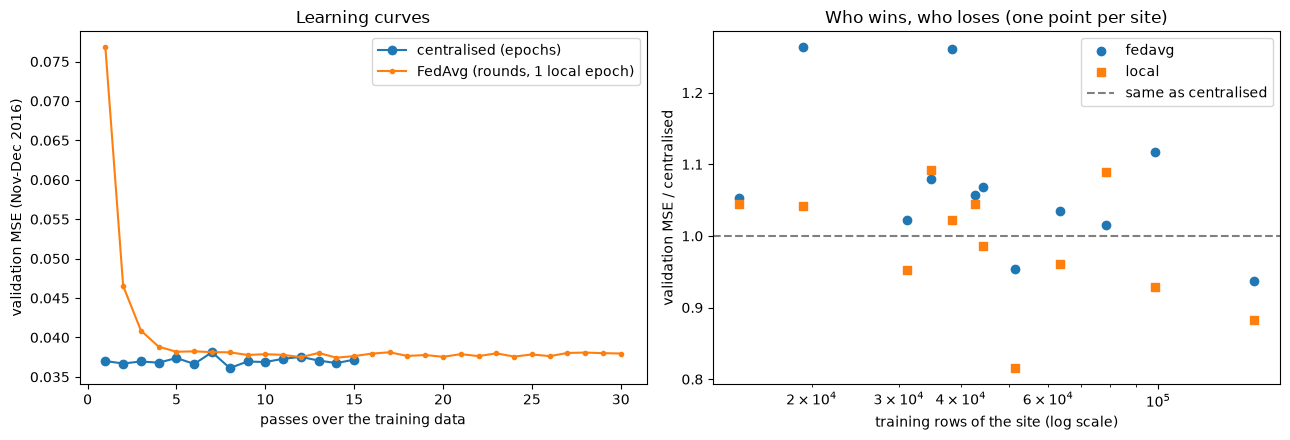

In [8]:
best_c, best_f = int(np.argmin(curve_c)), int(np.argmin(curve_f))
table = info.copy()
table["central"] = site_c[best_c]
table["fedavg"] = site_f[best_f]
table["local"] = pd.Series({s: min(c) for s, c in local_curves.items()})
table["local_best_epoch"] = pd.Series({s: int(np.argmin(c)) + 1 for s, c in local_curves.items()})
w = table["val_rows"] / table["val_rows"].sum()
print("best centralised epoch:", best_c + 1, " best FedAvg round:", best_f + 1)
print("overall validation MSE (row-weighted):")
print((table[["central", "fedavg", "local"]].mul(w, axis=0)).sum().round(4))
print(table.round(4).to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(range(1, len(curve_c) + 1), curve_c, marker="o", label="centralised (epochs)")
axes[0].plot(range(1, len(curve_f) + 1), curve_f, marker=".", label="FedAvg (rounds, 1 local epoch)")
axes[0].set(xlabel="passes over the training data", ylabel="validation MSE (Nov-Dec 2016)",
            title="Learning curves")
axes[0].legend()
for col, mk in [("fedavg", "o"), ("local", "s")]:
    axes[1].scatter(table["fit_rows"], table[col] / table["central"], marker=mk, label=col)
axes[1].axhline(1, color="gray", ls="--", label="same as centralised")
axes[1].set_xscale("log")
axes[1].set(xlabel="training rows of the site (log scale)", ylabel="validation MSE / centralised",
            title="Who wins, who loses (one point per site)")
axes[1].legend()
fig.tight_layout()
fig.savefig("../results/figures/m4_step1_validation.png", dpi=150)

In [9]:
month_v = month[is_val]
nov, dec = month_v == 11, month_v == 12          # choose on November, report December
site_rows = {s: np.flatnonzero(site_v == s) for s in sites}


def pick_one(preds):
    """One choice for everyone (centralised, FedAvg): the step with the lowest November MSE."""
    nov_mse = [np.mean((p[nov] - yv[nov]) ** 2) for p in preds]
    k = int(np.argmin(nov_mse))
    return k, preds[k]


def pick_per_site(preds_by_site):
    """Each site chooses its own step on its own November rows (local-only, fine-tuning)."""
    out, chosen = np.empty(len(yv)), {}
    for s, plist in preds_by_site.items():
        rows = site_rows[s]
        n_s = nov[rows]
        nov_mse = [np.mean((p[n_s] - yv[rows][n_s]) ** 2) for p in plist]
        k = int(np.argmin(nov_mse))
        out[rows], chosen[s] = plist[k], k
    return chosen, out


def december(pred):
    se = pd.Series((pred - yv) ** 2)[dec]
    return se.mean(), se.groupby(site_v[dec]).mean()


def train_central(init, seed, epochs=15):
    m = make_mlp()
    m.load_state_dict(init)
    opt = torch.optim.Adam(m.parameters(), lr=1e-3)
    gen = torch.Generator().manual_seed(seed)
    preds = []
    for _ in range(epochs):
        run_epoch(m, opt, Xf, yf, gen)
        preds.append(predict(m, Xv))
    return preds


def train_fedavg(init, seed, rounds, local_epochs):
    g = make_mlp()
    g.load_state_dict(init)
    gen = torch.Generator().manual_seed(seed)
    preds, states = [], []
    for _ in range(rounds):
        new_state = {k: torch.zeros_like(v) for k, v in g.state_dict().items()}
        for s in sites:
            local = copy.deepcopy(g)
            opt = torch.optim.Adam(local.parameters(), lr=1e-3)
            for _ in range(local_epochs):
                run_epoch(local, opt, *clients[s], gen)
            for k, v in local.state_dict().items():
                new_state[k] += n_k[s] / N * v
        g.load_state_dict(new_state)
        preds.append(predict(g, Xv))
        states.append(copy.deepcopy(new_state))
    return preds, states


def train_per_site(start_state, seed, epochs, include_start=False):
    """Every site trains its own copy of start_state; predictions on its own validation rows."""
    out = {}
    for s in sites:
        m = make_mlp()
        m.load_state_dict(start_state)
        opt = torch.optim.Adam(m.parameters(), lr=1e-3)
        gen = torch.Generator().manual_seed(seed)
        Xs_v = Xv[torch.from_numpy(site_v == s)]
        plist = [predict(m, Xs_v)] if include_start else []
        for _ in range(epochs):
            run_epoch(m, opt, *clients[s], gen)
            plist.append(predict(m, Xs_v))
        out[s] = plist
    return out